In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

In [2]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

print("First five rows:")
print(X.head())
print("\nDataset shape:", X.shape)
print("\nMissing values:\n", X.isnull().sum())
print("\nTarget classes:", iris.target_names)

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset shape: (150, 4)

Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Target classes: ['setosa' 'versicolor' 'virginica']


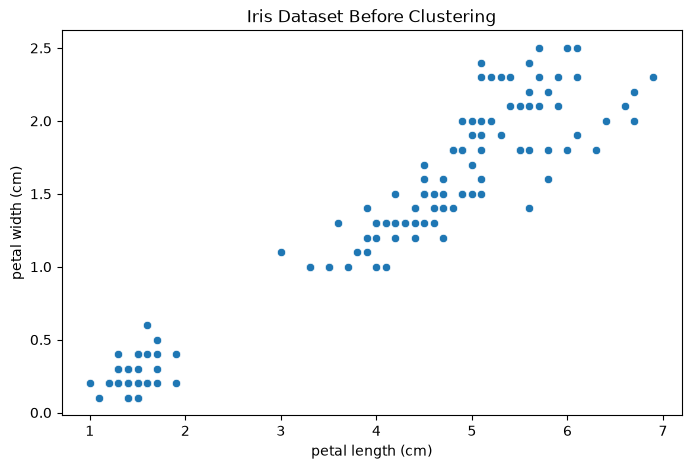

In [3]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=X,
    x="petal length (cm)",
    y="petal width (cm)"
)
plt.title("Iris Dataset Before Clustering")
plt.show()

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
from sklearn_extra.cluster import KMedoids

model = KMedoids(
    n_clusters=3,
    random_state=42,
    metric="euclidean"
)

labels = model.fit_predict(X_scaled)
print("Cluster labels:")
print(labels)

Cluster labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 1 1 1 2 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1
 1 2 2 2 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 2 2 2 1 2 2 2 2
 2 2 1 1 2 2 2 2 1 2 1 2 1 2 2 1 1 2 2 2 2 2 1 1 2 2 2 1 2 2 2 1 2 2 2 1 2
 2 1]


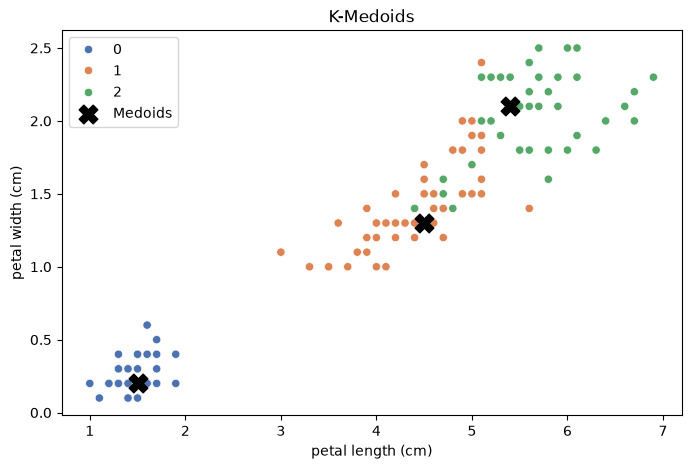

In [7]:
X_plot = X[["petal length (cm)", "petal width (cm)"]].copy()
X_plot["Cluster"] = labels

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=X_plot,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="Cluster",
    palette="deep"
)

medoid_indices = model.medoid_indices_
medoids = X.iloc[medoid_indices]
plt.scatter(
    medoids["petal length (cm)"],
    medoids["petal width (cm)"],
    marker="X",
    s=180,
    color="black",
    label="Medoids"
)

plt.title("K-Medoids")
plt.legend()
plt.show()